In [2]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score


In [9]:
#  Load Datasets
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")


# --- Exploratory Data Analysis ---

In [10]:
red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [11]:
white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [15]:
# Descriptive statistics
stats_red = red.describe().T
stats_red["variance"] = red.var()
stats_red["range"] = red.max() - red.min()
print(stats_red)


                       count       mean        std      min      25%  \
fixed acidity         1599.0   8.319637   1.741096  4.60000   7.1000   
volatile acidity      1599.0   0.527821   0.179060  0.12000   0.3900   
citric acid           1599.0   0.270976   0.194801  0.00000   0.0900   
residual sugar        1599.0   2.538806   1.409928  0.90000   1.9000   
chlorides             1599.0   0.087467   0.047065  0.01200   0.0700   
free sulfur dioxide   1599.0  15.874922  10.460157  1.00000   7.0000   
total sulfur dioxide  1599.0  46.467792  32.895324  6.00000  22.0000   
density               1599.0   0.996747   0.001887  0.99007   0.9956   
pH                    1599.0   3.311113   0.154386  2.74000   3.2100   
sulphates             1599.0   0.658149   0.169507  0.33000   0.5500   
alcohol               1599.0  10.422983   1.065668  8.40000   9.5000   
quality               1599.0   5.636023   0.807569  3.00000   5.0000   

                           50%        75%        max     varian

In [16]:
stats_white = white.describe().T
stats_white["variance"] = white.var()
stats_white["range"] = white.max() - white.min()
print(stats_white)


                       count        mean        std      min         25%  \
fixed acidity         4898.0    6.854788   0.843868  3.80000    6.300000   
volatile acidity      4898.0    0.278241   0.100795  0.08000    0.210000   
citric acid           4898.0    0.334192   0.121020  0.00000    0.270000   
residual sugar        4898.0    6.391415   5.072058  0.60000    1.700000   
chlorides             4898.0    0.045772   0.021848  0.00900    0.036000   
free sulfur dioxide   4898.0   35.308085  17.007137  2.00000   23.000000   
total sulfur dioxide  4898.0  138.360657  42.498065  9.00000  108.000000   
density               4898.0    0.994027   0.002991  0.98711    0.991723   
pH                    4898.0    3.188267   0.151001  2.72000    3.090000   
sulphates             4898.0    0.489847   0.114126  0.22000    0.410000   
alcohol               4898.0   10.514267   1.230621  8.00000    9.500000   
quality               4898.0    5.877909   0.885639  3.00000    5.000000   

           

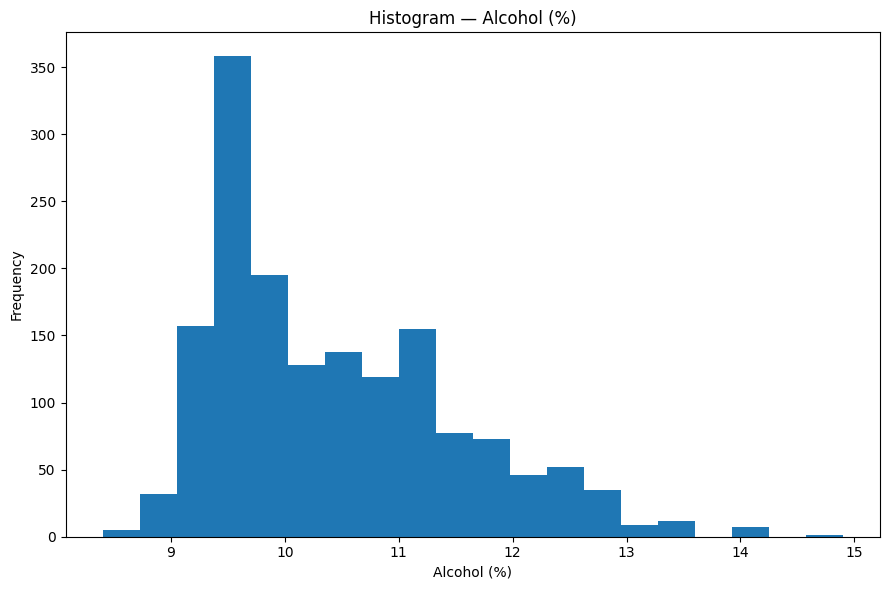

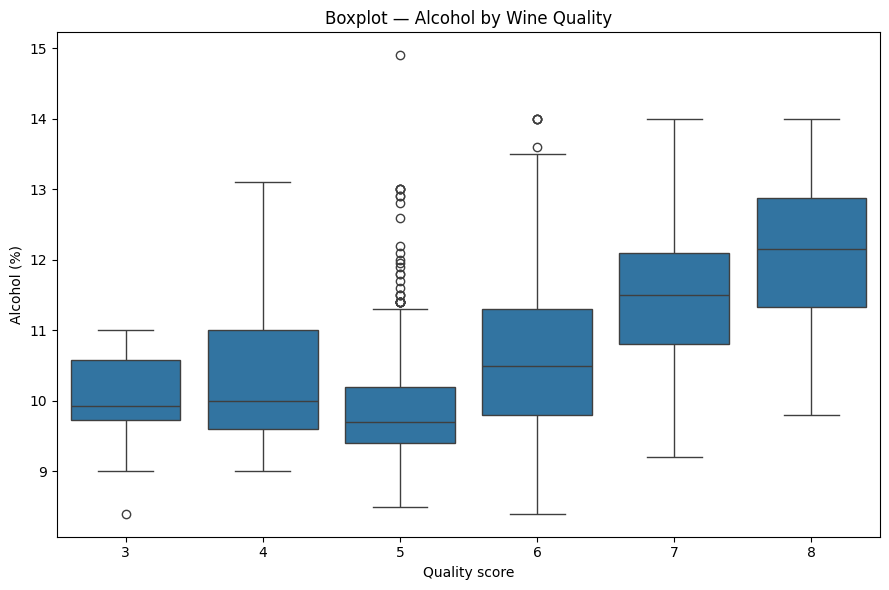

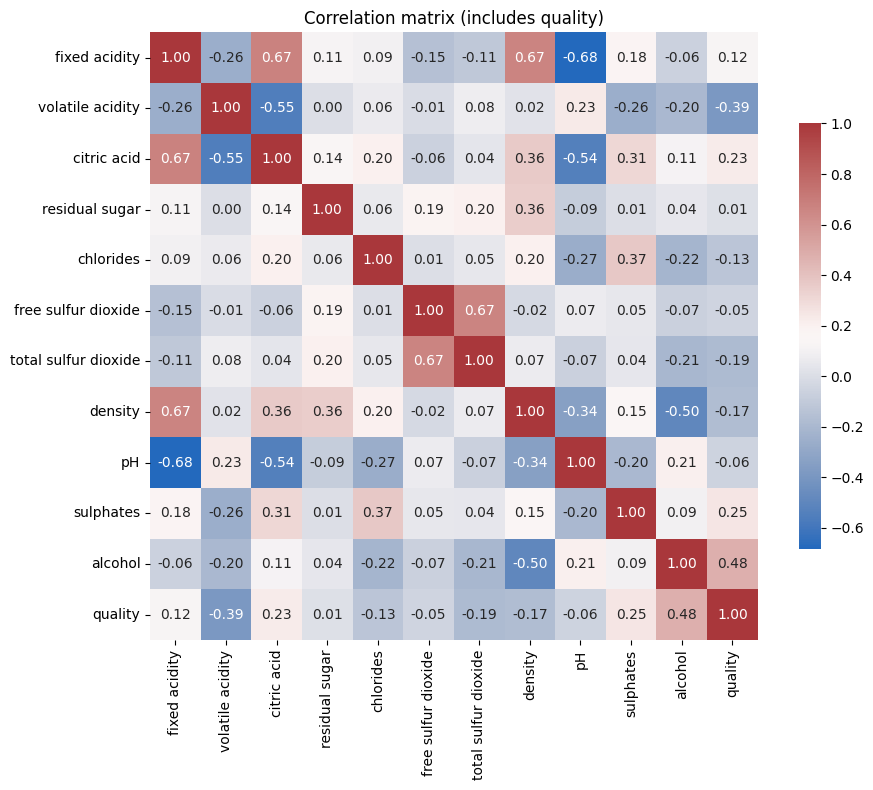

In [17]:
# 1(b) Visualizations for red
plt.rcParams.update({'figure.figsize': (9,6)})

# 1) Histogram of Alcohol
plt.figure()
plt.hist(red['alcohol'].dropna(), bins=20)
plt.title('Histogram — Alcohol (%)')
plt.xlabel('Alcohol (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# 2) Boxplot: Alcohol by Quality
plt.figure()
order = sorted(red['quality'].unique())
sns.boxplot(x='quality', y='alcohol', data=red, order=order)
plt.title('Boxplot — Alcohol by Wine Quality')
plt.xlabel('Quality score')
plt.ylabel('Alcohol (%)')
plt.tight_layout()
plt.show()

# 3) Correlation heatmap (predictors + quality)
plt.figure(figsize=(10,8))
corr = red.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", square=True, cbar_kws={'shrink':0.7})
plt.title('Correlation matrix (includes quality)')
plt.tight_layout()
plt.show()


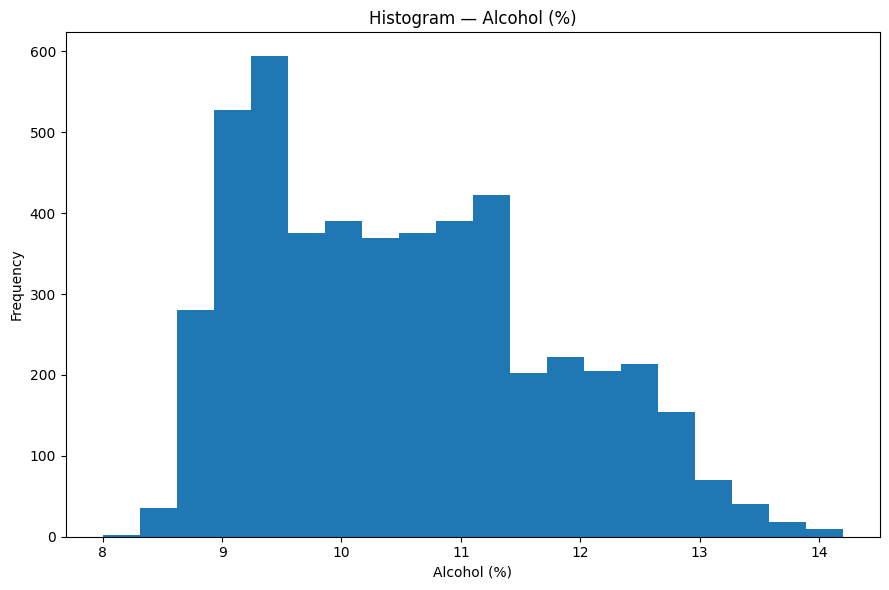

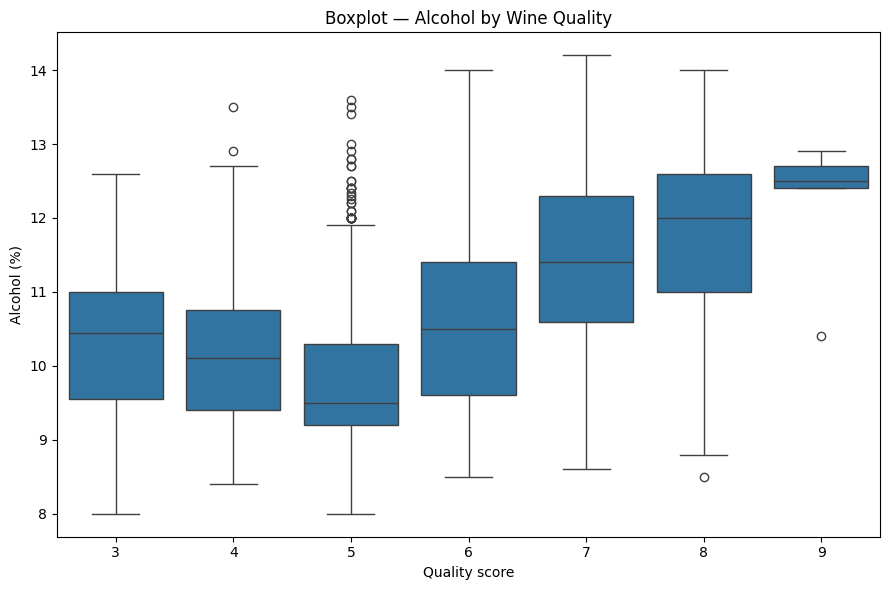

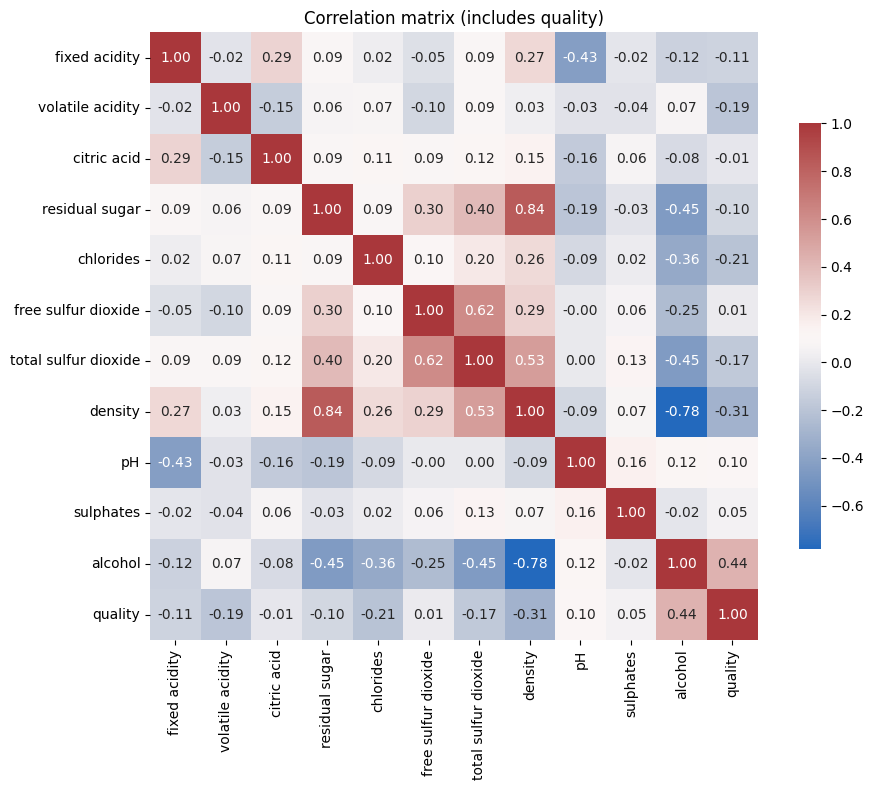

In [18]:
# 1(b) Visualizations for white
plt.rcParams.update({'figure.figsize': (9,6)})

# 1) Histogram of Alcohol
plt.figure()
plt.hist(white['alcohol'].dropna(), bins=20)
plt.title('Histogram — Alcohol (%)')
plt.xlabel('Alcohol (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# 2) Boxplot: Alcohol by Quality
plt.figure()
order = sorted(white['quality'].unique())
sns.boxplot(x='quality', y='alcohol', data=white, order=order)
plt.title('Boxplot — Alcohol by Wine Quality')
plt.xlabel('Quality score')
plt.ylabel('Alcohol (%)')
plt.tight_layout()
plt.show()

# 3) Correlation heatmap (predictors + quality)
plt.figure(figsize=(10,8))
corr = white.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", square=True, cbar_kws={'shrink':0.7})
plt.title('Correlation matrix (includes quality)')
plt.tight_layout()
plt.show()


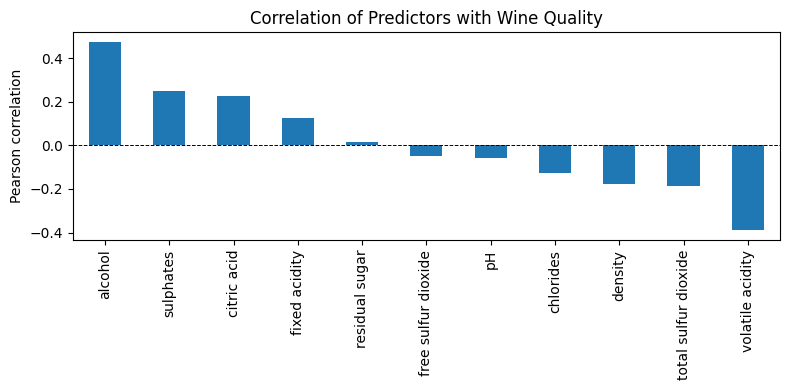

In [19]:
# Correlation of each predictor with 'quality' with red
corr_with_quality = red.corr()['quality'].drop('quality').sort_values(ascending=False).round(4)

# Display as a neat table
corr_with_quality.to_frame(name="correlation_with_quality")

# Bar plot for quick visualization
plt.figure(figsize=(8,4))
corr_with_quality.plot(kind='bar')
plt.title("Correlation of Predictors with Wine Quality")
plt.ylabel("Pearson correlation")
plt.axhline(0, color='k', linestyle='--', linewidth=0.7)
plt.tight_layout()
plt.show()

Interpretation (how you can write it in your notebook)

Strongest positive: alcohol (≈ +0.48). Wines with more alcohol tend to be rated higher quality.

Moderate positives: sulphates (+0.25) and citric acid (+0.23). Both contribute to taste structure and freshness.

Weak positives: fixed acidity (+0.12) and residual sugar (~0.01, nearly no effect).

Strongest negative: volatile acidity (≈ −0.39). High VA gives vinegar-like taste, lowering quality.

Moderate negatives: total sulfur dioxide (−0.18), density (−0.17), chlorides (−0.13). Excess of these reduces quality.

Very weak negatives: pH and free sulfur dioxide.

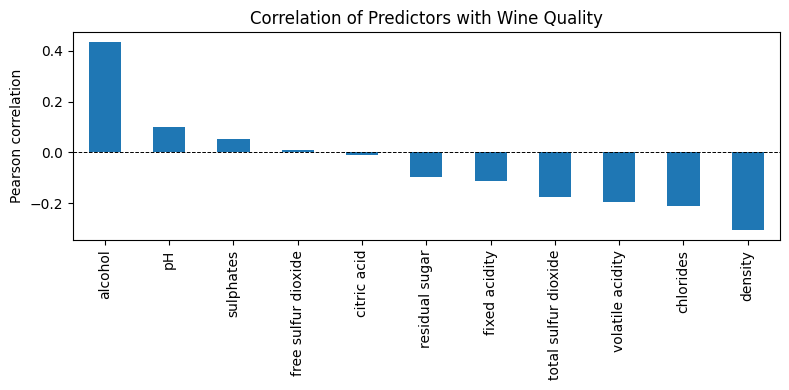

In [20]:
# Correlation of each predictor with 'quality' with white
corr_with_quality = white.corr()['quality'].drop('quality').sort_values(ascending=False).round(4)

# Display as a neat table
corr_with_quality.to_frame(name="correlation_with_quality")

# Bar plot for quick visualization
plt.figure(figsize=(8,4))
corr_with_quality.plot(kind='bar')
plt.title("Correlation of Predictors with Wine Quality")
plt.ylabel("Pearson correlation")
plt.axhline(0, color='k', linestyle='--', linewidth=0.7)
plt.tight_layout()
plt.show()